# Huấn luyện YOLOv8n nhận diện mệnh giá tiền Việt Nam (VND) cho ứng dụng Mắt Việt

**Mục tiêu:** phát hiện tờ tiền trong khung hình camera (khung bao) và phân loại mệnh giá, chạy **100% trên thiết bị** bằng TensorFlow Lite.

**Vì sao chọn YOLOv8n thay cho phân loại MobileNetV3:**
- Model phân loại cũ chỉ cho biết "cả ảnh là tờ gì", không biết tờ tiền nằm đâu. App phải cắt 7–31 vùng và chạy model nhiều lần mỗi khung hình (0,4–1,8 giây trên S25 FE), lại dễ đọc nhầm từ một mẩu cắt.
- YOLO trả về **khung bao + mệnh giá trong 1 lần chạy**, đúng kiểu hiển thị của Google Lookout.
- Chọn bản **n (nano)** vì app đã chạy YOLOv8n trên S25 FE ở chế độ vật cản (đường export ONNX → TFLite và bộ giải mã đã kiểm chứng). YOLO11n mới hơn nhưng chưa kiểm chứng đường export trong dự án, rủi ro khi còn ít ngày.

**Dữ liệu:**
- `data/raw/tienviet/`: Roboflow Universe *danhdz/tienviet v5* (CC BY 4.0), 9 mệnh giá 1.000 → 500.000 đ, định dạng YOLOv8.
- `data/raw/none/`: ảnh **không phải tiền** (COCO val2017). Trong YOLO, "không phải tiền" được biểu diễn bằng **ảnh nền không có khung** (file nhãn rỗng), không phải một lớp riêng. Model học cách *không* phát hiện gì; app hiểu "không có khung" = không có tiền.

**Quy trình:**
1. Kiểm tra môi trường và cấu hình
2. Khảo sát dataset gốc và phát hiện rò rỉ dữ liệu
3. Tạo ảnh `none` (không phải tiền)
4. Chia lại train/val/test **theo nhóm ảnh gốc** (chống rò rỉ)
5. Huấn luyện YOLOv8n
6. Đánh giá trên tập test: mAP và chỉ số cấp ảnh theo cách app dùng
7. Xuất model (ONNX, TFLite nếu nền tảng hỗ trợ) và lưu metrics

In [1]:
# @title Bước 1: Kiểm tra môi trường phần cứng và thư viện
import sys, os, subprocess, importlib

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics', 'imagehash'], check=True)

import platform, json, random, re, shutil, time, zipfile, io, urllib.request
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps
import torch
import ultralytics
from ultralytics import YOLO
import imagehash

print('=' * 60)
print(f'- Python:       {sys.version.split()[0]} ({platform.system()})')
print(f'- PyTorch:      {torch.__version__}')
print(f'- Ultralytics:  {ultralytics.__version__}')
print(f'- CUDA:         {torch.cuda.is_available()}')
if torch.cuda.is_available():
    p = torch.cuda.get_device_properties(0)
    print(f'- GPU:          {p.name} ({p.total_memory / 1024**3:.1f} GB)')
else:
    print('[CANH BAO] Khong co GPU, huan luyen tren CPU se rat cham.')
print('=' * 60)

- Python:       3.11.9 (Windows)
- PyTorch:      2.5.1+cu121
- Ultralytics:  8.4.200
- CUDA:         True
- GPU:          NVIDIA GeForce RTX 3050 Laptop GPU (4.0 GB)


## Bước 2: Cấu hình đường dẫn và tham số huấn luyện

In [2]:
# @title Bang cau hinh chinh
def find_ml_root() -> Path:
    # Tim thu muc ml_training (notebook nam trong ml_training/notebooks).
    p = Path.cwd().resolve()
    for cand in [p, *p.parents]:
        if cand.name == 'ml_training':
            return cand
        if (cand / 'ml_training').is_dir():
            return cand / 'ml_training'
    return p

ML_ROOT      = find_ml_root()
RAW_DIR      = ML_ROOT / 'data' / 'raw' / 'tienviet'      # dataset Roboflow da tai
NONE_DIR     = ML_ROOT / 'data' / 'raw' / 'none'          # anh khong phai tien
CACHE_DIR    = ML_ROOT / 'data' / 'cache'
DATASET_DIR  = ML_ROOT / 'data' / 'currency_yolo'         # dataset da chia lai cho YOLO
OUTPUT_DIR   = ML_ROOT / 'outputs' / 'currency_yolo'
for d in (NONE_DIR, CACHE_DIR, OUTPUT_DIR):
    d.mkdir(parents=True, exist_ok=True)

RANDOM_SEED  = 42
NONE_COUNT   = 600          # so anh nen (khong phai tien) lay tu COCO val2017
SPLIT        = (0.8, 0.1, 0.1)
# Nguong Hamming gom anh trung (bat bien xoay/lat). Da thu: 0 -> 537 nhom (lop lon nhat 14%);
# >= 2 -> chuoi khung hinh chup lien tiep dinh thanh 1 nhom chiem 40-90% moi lop, khong the chia test.
PHASH_DIST   = 0

MODEL_NAME   = 'yolov8n.pt'
IMG_SIZE     = 640          # anh Roboflow da duoc resize 640x640
EPOCHS       = 60
BATCH        = 16           # vua 4 GB VRAM voi YOLOv8n @ 640
PATIENCE     = 15
WORKERS      = 4
APP_CONF     = 0.5          # nguong tin cay app dung de coi la "co tien"

# Ten lop ngan, khop voi Denomination.fromCode trong app ('1k', '10k', ...)
SHORT_NAMES = {'1 000 VND': '1k', '2 000 VND': '2k', '5 000 VND': '5k', '10 000 VND': '10k',
               '20 000 VND': '20k', '50 000 VND': '50k', '100 000 VND': '100k',
               '200 000 VND': '200k', '500 000 VND': '500k'}

random.seed(RANDOM_SEED); np.random.seed(RANDOM_SEED); torch.manual_seed(RANDOM_SEED)
print(f'[INFO] ML_ROOT     = {ML_ROOT}')
print(f'[INFO] Dataset goc = {RAW_DIR} (ton tai: {RAW_DIR.exists()})')
print(f'[INFO] Ket qua     = {OUTPUT_DIR}')
print(f'[INFO] Model {MODEL_NAME}, imgsz={IMG_SIZE}, epochs={EPOCHS}, batch={BATCH}')

[INFO] ML_ROOT     = C:\Personal_data\CDCNTT\Project\vision_assist\ml_training
[INFO] Dataset goc = C:\Personal_data\CDCNTT\Project\vision_assist\ml_training\data\raw\tienviet (ton tai: True)
[INFO] Ket qua     = C:\Personal_data\CDCNTT\Project\vision_assist\ml_training\outputs\currency_yolo
[INFO] Model yolov8n.pt, imgsz=640, epochs=60, batch=16


## Bước 3: Khảo sát dataset gốc và phát hiện rò rỉ dữ liệu
Roboflow đặt tên file dạng `<ảnh gốc>_jpg.rf.<mã>.jpg`; mỗi ảnh gốc được nhân 3 bản bằng lật ngang/dọc, nghiêng và nhiễu. Nếu cùng một ảnh gốc nằm ở cả train và test thì điểm test bị **thổi phồng**.

Lop (theo chi so): {0: '1k', 1: '10k', 2: '100k', 3: '2k', 4: '20k', 5: '200k', 6: '5k', 7: '50k', 8: '500k'}


            so_anh  so_anh_goc
orig_split                    
test           300         200
train         3150         641
valid          150         128

[RO RI] anh goc chung train-valid: 58, train-test: 64, valid-test: 50
So khung moi anh: {1: 3597, 0: 3}
Dien tich khung / anh: p10=0.41, median=0.92, p90=0.99


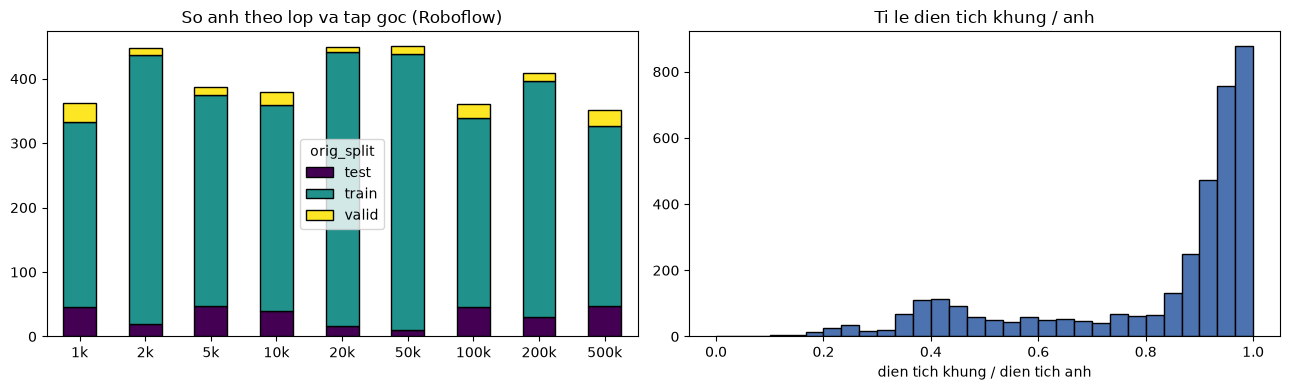

In [3]:
# @title Thong ke so anh, so anh goc, phan bo lop va ro ri giua cac tap
import yaml
with open(RAW_DIR / 'data.yaml', encoding='utf-8') as f:
    raw_yaml = yaml.safe_load(f)
RAW_NAMES = raw_yaml['names']
CLASS_NAMES = [SHORT_NAMES[n] for n in RAW_NAMES]   # giu nguyen thu tu chi so cua Roboflow
print('Lop (theo chi so):', dict(enumerate(CLASS_NAMES)))

SRC_RE = re.compile(r'^(.*)_(jpg|jpeg|png)\.rf\.[0-9a-f]+\.\w+$', re.I)
def source_of(fname):
    m = SRC_RE.match(fname)
    return m.group(1) if m else Path(fname).stem

records = []
for split in ('train', 'valid', 'test'):
    for img in sorted((RAW_DIR / split / 'images').iterdir()):
        lab = RAW_DIR / split / 'labels' / (img.stem + '.txt')
        lines = [l.split() for l in lab.read_text().splitlines() if l.strip()] if lab.exists() else []
        classes = sorted({int(l[0]) for l in lines})
        areas = [float(l[3]) * float(l[4]) for l in lines]
        records.append({'path': img, 'label_path': lab, 'orig_split': split, 'source': source_of(img.name),
                        'n_boxes': len(lines), 'cls': classes[0] if classes else -1,
                        'area': max(areas) if areas else 0.0})
df = pd.DataFrame(records)

summary = df.groupby('orig_split').agg(so_anh=('path', 'size'), so_anh_goc=('source', 'nunique'))
print(summary.to_string())
srcs = {s: set(df[df.orig_split == s].source) for s in ('train', 'valid', 'test')}
print(f"\n[RO RI] anh goc chung train-valid: {len(srcs['train'] & srcs['valid'])}, "
      f"train-test: {len(srcs['train'] & srcs['test'])}, valid-test: {len(srcs['valid'] & srcs['test'])}")
print(f"So khung moi anh: {dict(Counter(df.n_boxes))}")
print(f"Dien tich khung / anh: p10={df.area.quantile(.1):.2f}, median={df.area.median():.2f}, p90={df.area.quantile(.9):.2f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
cnt = df[df.cls >= 0].assign(lop=lambda d: d.cls.map(lambda i: CLASS_NAMES[i])).groupby(['lop', 'orig_split']).size().unstack(fill_value=0)
cnt = cnt.loc[[c for c in ['1k','2k','5k','10k','20k','50k','100k','200k','500k'] if c in cnt.index]]
cnt.plot(kind='bar', stacked=True, ax=ax[0], colormap='viridis', edgecolor='black')
ax[0].set_title('So anh theo lop va tap goc (Roboflow)'); ax[0].set_xlabel(''); ax[0].tick_params(axis='x', rotation=0)
ax[1].hist(df.area, bins=30, color='#4c72b0', edgecolor='black')
ax[1].set_title('Ti le dien tich khung / anh'); ax[1].set_xlabel('dien tich khung / dien tich anh')
plt.tight_layout(); plt.show()

## Bước 4: Tạo ảnh `none` (không phải tiền) từ COCO val2017
- Lấy ngẫu nhiên **600 ảnh** COCO val2017 (đồ vật, người, bàn ghế, phòng ở...).
- **Một nửa được cắt cận cảnh** (30–70% kích thước) để mô phỏng việc người khiếm thị đưa camera sát vật.
- Thu nhỏ cạnh dài tối đa 640 px, lưu vào `data/raw/none/`. Bỏ qua nếu đã có đủ ảnh.
- Khi đưa vào YOLO, mỗi ảnh `none` có **file nhãn rỗng** (ảnh nền). Ultralytics khuyến nghị khoảng 0–10% ảnh nền để giảm báo nhầm.

[INFO] Da co 600 anh none, bo qua buoc tai.


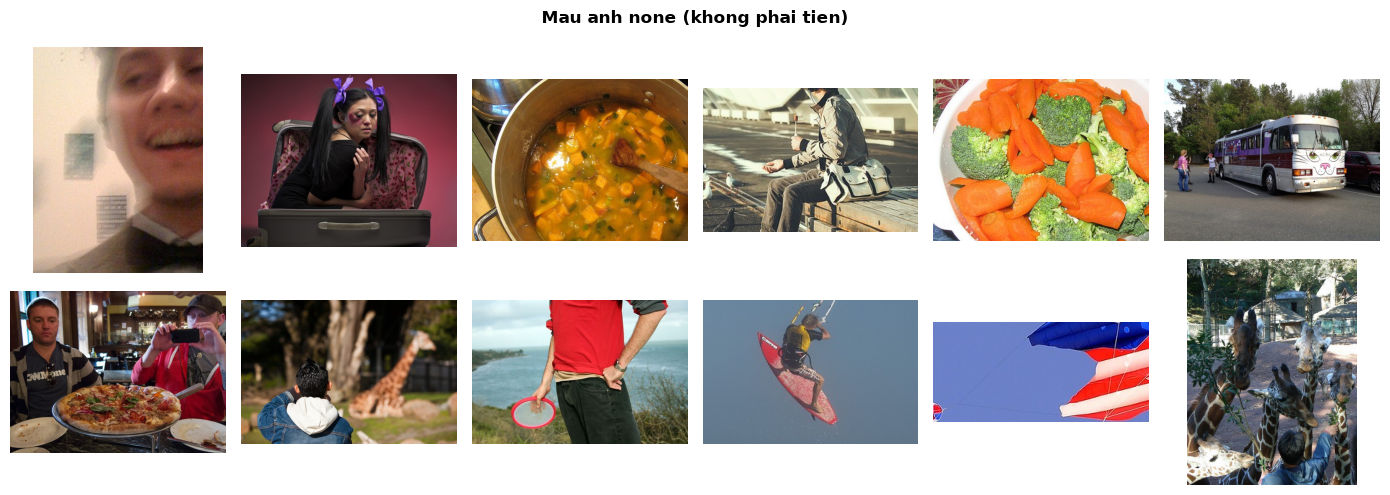

In [4]:
# @title Tai COCO val2017 va tao anh none
existing = sorted(NONE_DIR.glob('*.jpg'))
if len(existing) >= NONE_COUNT:
    print(f'[INFO] Da co {len(existing)} anh none, bo qua buoc tai.')
else:
    zip_path = CACHE_DIR / 'val2017.zip'
    if not zip_path.exists():
        url = 'http://images.cocodataset.org/zips/val2017.zip'
        print(f'[INFO] Dang tai {url} (~780 MB)...')
        t0 = time.time()
        def hook(blocks, bs, total, _last=[0]):
            done = blocks * bs
            if done - _last[0] >= 100 * 1024**2 or done >= total:
                _last[0] = done
                print(f'   - {done / 1024**2:6.0f} / {total / 1024**2:.0f} MB')
        urllib.request.urlretrieve(url, zip_path, reporthook=hook)
        print(f'[INFO] Tai xong trong {time.time() - t0:.0f}s')
    rng = random.Random(RANDOM_SEED)
    with zipfile.ZipFile(zip_path) as zf:
        members = [m for m in zf.namelist() if m.lower().endswith('.jpg')]
        chosen = rng.sample(members, NONE_COUNT)
        for i, m in enumerate(chosen):
            with Image.open(io.BytesIO(zf.read(m))) as im:
                im = ImageOps.exif_transpose(im).convert('RGB')
                if i < NONE_COUNT // 2:   # cat can canh
                    w, h = im.size; r = rng.uniform(0.3, 0.7)
                    cw, ch = max(32, int(w * r)), max(32, int(h * r))
                    x, y = rng.randint(0, w - cw), rng.randint(0, h - ch)
                    im = im.crop((x, y, x + cw, y + ch))
                im.thumbnail((640, 640), Image.Resampling.LANCZOS)
                im.save(NONE_DIR / f'coco_none_{i:04d}.jpg', quality=90)
    zip_path.unlink()   # giai phong o dia
    print(f'[SUCCESS] Da tao {len(list(NONE_DIR.glob("*.jpg")))} anh none tai {NONE_DIR}')

none_paths = sorted(NONE_DIR.glob('*.jpg'))[:NONE_COUNT]
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax, p in zip(axes.flat, random.Random(1).sample(none_paths, 12)):
    ax.imshow(Image.open(p)); ax.axis('off')
plt.suptitle('Mau anh none (khong phai tien)', fontweight='bold'); plt.tight_layout(); plt.show()

## Bước 5: Chia lại train / val / test theo nhóm (chống rò rỉ)
1. **Nhóm theo ảnh gốc**: 3 bản tăng cường của cùng một ảnh luôn vào cùng một tập.
2. **Nhóm thêm theo ảnh trùng**: perceptual hash, có tính cả 8 phép xoay/lật vì Roboflow đã lật ảnh. Các ảnh trùng hoàn toàn nhưng mang tên ảnh gốc khác nhau (cùng một ảnh tải lên nhiều lần) được gộp chung nhóm (Union-Find).
   - *Đã thử nới ngưỡng*: khoảng cách ≥ 2 làm chuỗi khung hình chụp liên tiếp cùng một tờ tiền dính thành một nhóm chiếm 40–90% mỗi lớp, không thể tách tập test. Vì vậy các khung hình **gần giống** (không trùng hẳn) vẫn có thể nằm ở cả train và test. Đây là giới hạn của dataset.
3. Chia **khoảng 80/10/10 theo nhóm**, riêng từng lớp. Nhóm quá lớn được để lại cho train, để val/test lớp nào cũng có ảnh.
4. Ở val/test chỉ giữ **1 bản cho mỗi ảnh gốc**, ưu tiên bản không tăng cường (từ tập valid/test gốc của Roboflow), để đánh giá sát ảnh thật hơn.
5. Ảnh `none` chia 80/10/10, nhãn rỗng.

In [5]:
# @title Gom nhom anh goc + anh gan trung, chia lai va ghi dataset YOLO
POP = np.array([bin(i).count('1') for i in range(256)], np.uint8)
def phash_variants(path):
    im = Image.open(path).convert('L')
    out = []
    for k in range(4):
        r = im.rotate(90 * k, expand=True)
        for v in (r, ImageOps.mirror(r)):
            out.append(np.packbits(imagehash.phash(v).hash.flatten()))
    return np.stack(out)          # (8, 8) bytes

t0 = time.time()
H = np.stack([phash_variants(p) for p in df.path])   # (N, 8 bien the, 8 byte)
print(f'[INFO] Tinh phash {len(df)} anh x 8 bien the trong {time.time() - t0:.0f}s')

parent = list(range(len(df)))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]; i = parent[i]
    return i
def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb: parent[ra] = rb

# 1) cung anh goc
for _, idx in df.groupby('source').groups.items():
    idx = list(idx)
    for j in idx[1:]: union(idx[0], j)
# 2) anh gan trung trong cung lop (so ban goc cua i voi 8 bien the cua j)
n_near = 0
for c, idx in df.groupby('cls').groups.items():
    idx = np.array(list(idx))
    base = H[idx, 0]                                    # (n, 8)
    for a in range(len(idx)):
        d = POP[np.bitwise_xor(H[idx[a + 1:]], base[a])].sum(-1).min(-1)
        for b in idx[a + 1:][d <= PHASH_DIST]:
            if find(idx[a]) != find(b): n_near += 1
            union(idx[a], b)
df['group'] = [find(i) for i in range(len(df))]
print(f'[INFO] {df.source.nunique()} anh goc -> {df.group.nunique()} nhom doc lap (gop them {n_near} cap anh trung)')

# Chia theo nhom, rieng tung lop: lap day test roi val toi ~10% so ANH GOC moi lop;
# nhom qua lon so voi phan con thieu thi de lai cho train (tranh 1 nhom lon chiem het tap test).
rng = random.Random(RANDOM_SEED)
split_of_group = {}
for c, sub in df.groupby('cls'):
    groups = sorted(sub.group.unique()); rng.shuffle(groups)
    n_src = sub.groupby('group').source.nunique()
    total = n_src.sum()
    need = {'test': SPLIT[2] * total, 'val': SPLIT[1] * total}
    for g in groups:
        for s in ('test', 'val'):
            if need[s] > 0 and n_src[g] <= max(1.0, need[s] * 1.2):
                split_of_group[g] = s; need[s] -= n_src[g]
                break
        else:
            split_of_group[g] = 'train'
df['split'] = df.group.map(split_of_group)

# val/test: 1 ban moi anh goc, uu tien ban tu tap valid/test goc (khong tang cuong)
df['prio'] = df.orig_split.map({'test': 0, 'valid': 0, 'train': 1})
keep = df[df.split == 'train']
evals = df[df.split != 'train'].sort_values(['source', 'prio']).groupby('source').head(1)
final = pd.concat([keep, evals])

# ghi dataset YOLO
if DATASET_DIR.exists(): shutil.rmtree(DATASET_DIR)
for s in ('train', 'val', 'test'):
    (DATASET_DIR / 'images' / s).mkdir(parents=True); (DATASET_DIR / 'labels' / s).mkdir(parents=True)
for r in final.itertuples():
    shutil.copy2(r.path, DATASET_DIR / 'images' / r.split / r.path.name)
    shutil.copy2(r.label_path, DATASET_DIR / 'labels' / r.split / r.label_path.name)
none_rng = random.Random(RANDOM_SEED); nps = list(none_paths); none_rng.shuffle(nps)
n_tr, n_va = int(len(nps) * SPLIT[0]), int(len(nps) * SPLIT[1])
none_split = {p: ('train' if i < n_tr else 'val' if i < n_tr + n_va else 'test') for i, p in enumerate(nps)}
for p, s in none_split.items():
    shutil.copy2(p, DATASET_DIR / 'images' / s / p.name)
    (DATASET_DIR / 'labels' / s / (p.stem + '.txt')).write_text('')   # nhan rong = anh nen

data_yaml = DATASET_DIR / 'data.yaml'
data_yaml.write_text(yaml.safe_dump({'path': str(DATASET_DIR), 'train': 'images/train', 'val': 'images/val',
                                     'test': 'images/test', 'names': dict(enumerate(CLASS_NAMES))},
                                    allow_unicode=True, sort_keys=False), encoding='utf-8')

rows = []
for s in ('train', 'val', 'test'):
    sub = final[final.split == s]
    row = {'Tap': s, 'Anh tien': len(sub), 'Anh goc': sub.source.nunique(),
           'Anh none': sum(1 for v in none_split.values() if v == s)}
    row.update({CLASS_NAMES[c]: int((sub.cls == c).sum()) for c in range(len(CLASS_NAMES))})
    rows.append(row)
split_df = pd.DataFrame(rows)
print(split_df.to_string(index=False))
leak = set(final[final.split == 'train'].group) & set(final[final.split != 'train'].group)
print(f'\n[KIEM TRA] Nhom xuat hien o ca train va val/test: {len(leak)} (phai = 0)')
# Muc do "gan giong" con lai: anh test co anh train cung lop voi khoang cach phash nho
pos = {p: i for i, p in enumerate(df.path)}
tr_idx = np.array([pos[p] for p in final[final.split == 'train'].path])
te = final[final.split == 'test']
near_d = []
for r in te.itertuples():
    cand = tr_idx[df.cls.values[tr_idx] == r.cls]
    if r.cls < 0 or len(cand) == 0:
        continue
    near_d.append(int(POP[np.bitwise_xor(H[cand], H[pos[r.path], 0])].sum(-1).min()))
near_d = np.array(near_d)
print(f'[GIOI HAN] Anh test co anh train cung lop gan giong (phash <= 4): {100 * (near_d <= 4).mean():.0f}% '
      f'| <= 8: {100 * (near_d <= 8).mean():.0f}% -> diem test van lac quan so voi thuc te')
none_pct = 100 * split_df['Anh none'].sum() / (split_df['Anh none'].sum() + split_df['Anh tien'].sum())
print(f'[INFO] Ti le anh none: {none_pct:.1f}%')
print(f'[SUCCESS] Da ghi dataset YOLO tai {DATASET_DIR}')

[INFO] Tinh phash 3600 anh x 8 bien the trong 27s


[INFO] 801 anh goc -> 537 nhom doc lap (gop them 264 cap anh trung)


  Tap  Anh tien  Anh goc  Anh none  1k  10k  100k  2k  20k  200k  5k  50k  500k
train      3014      654       480 331  320   296 422  360   334 323  360   268
  val        77       77        60   0    8     8   2   15    11  11   11    11
 test        70       70        60   7    8     7   5    8     5   8   12     9

[KIEM TRA] Nhom xuat hien o ca train va val/test: 0 (phai = 0)
[GIOI HAN] Anh test co anh train cung lop gan giong (phash <= 4): 20% | <= 8: 46% -> diem test van lac quan so voi thuc te
[INFO] Ti le anh none: 16.0%
[SUCCESS] Da ghi dataset YOLO tai C:\Personal_data\CDCNTT\Project\vision_assist\ml_training\data\currency_yolo


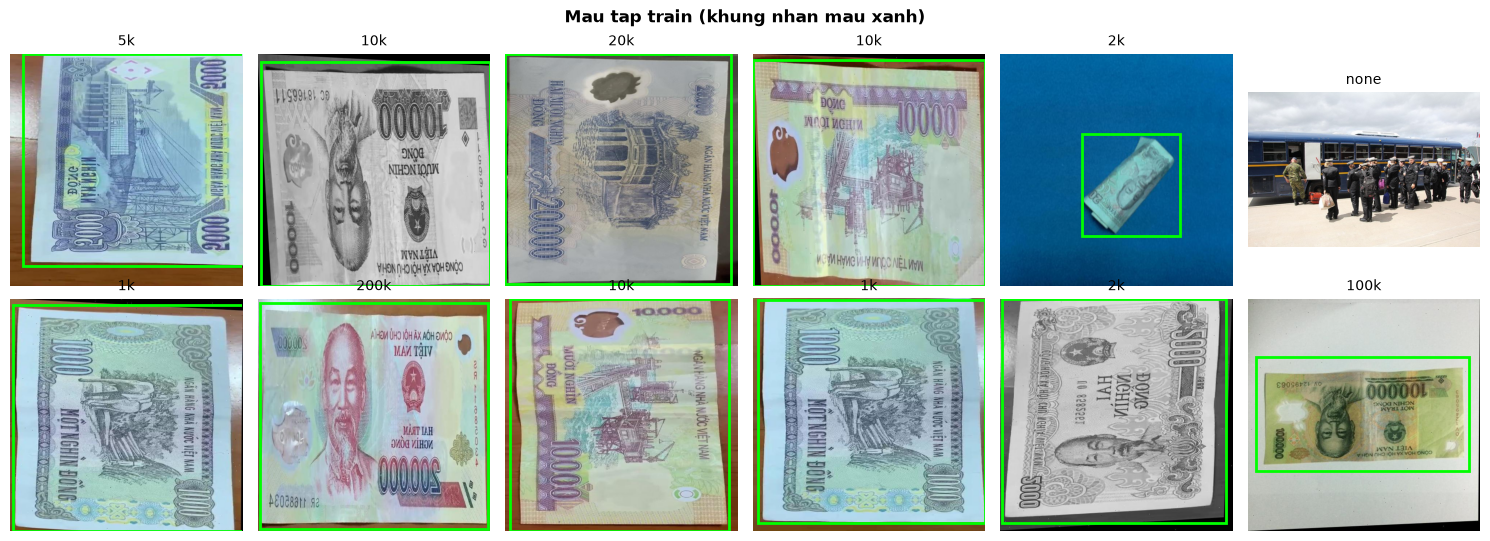

In [6]:
# @title Hien thi mau anh kem khung nhan sau khi chia
def draw_samples(split, n=12, seed=0):
    imgs = sorted((DATASET_DIR / 'images' / split).glob('*.jpg'))
    fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))
    for ax, p in zip(axes.flat, random.Random(seed).sample(imgs, n)):
        im = Image.open(p).convert('RGB'); W, Hh = im.size
        ax.imshow(im); ax.axis('off')
        lab = DATASET_DIR / 'labels' / split / (p.stem + '.txt')
        lines = [l.split() for l in lab.read_text().splitlines() if l.strip()]
        title = 'none'
        for l in lines:
            c, x, y, w, h = int(l[0]), *map(float, l[1:5])
            ax.add_patch(plt.Rectangle(((x - w / 2) * W, (y - h / 2) * Hh), w * W, h * Hh,
                                       fill=False, color='lime', lw=2))
            title = CLASS_NAMES[c]
        ax.set_title(title, fontsize=10)
    plt.suptitle(f'Mau tap {split} (khung nhan mau xanh)', fontweight='bold'); plt.tight_layout(); plt.show()
draw_samples('train')

## Bước 6: Huấn luyện YOLOv8n (transfer learning từ trọng số COCO)
Các lựa chọn tăng cường:
- `fliplr=0`, `flipud=0`: **không lật thêm**, vì lật gương làm chữ số tiền thành dạng không có thật. Dataset Roboflow đã chứa sẵn bản lật, phần này không gỡ được.
- `degrees=15`: tờ tiền bị cầm nghiêng.
- `hsv_*` mặc định: thay đổi màu và độ sáng.
- `mosaic` mặc định: tờ tiền xuất hiện ở nhiều kích thước và vị trí.
- `close_mosaic=10`: tắt mosaic ở 10 epoch cuối cho sát ảnh thật.

Dừng sớm nếu mAP trên tập val không cải thiện sau `patience` epoch.

In [7]:
# @title Huan luyen
model = YOLO(MODEL_NAME)
t0 = time.time()
train_results = model.train(
    data=str(data_yaml), imgsz=IMG_SIZE, epochs=EPOCHS, batch=BATCH, patience=PATIENCE,
    workers=WORKERS, seed=RANDOM_SEED, deterministic=False,
    fliplr=0.0, flipud=0.0, degrees=15.0, close_mosaic=10,
    project=str(OUTPUT_DIR), name='train', exist_ok=True, plots=True, verbose=False,
)
TRAIN_DIR = Path(train_results.save_dir)
BEST_PT = TRAIN_DIR / 'weights' / 'best.pt'
print(f'[SUCCESS] Huan luyen xong trong {(time.time() - t0) / 60:.1f} phut. Model tot nhat: {BEST_PT}')

New https://pypi.org/project/ultralytics/8.4.201 available  Update with 'pip install -U ultralytics'


Ultralytics 8.4.200  Python-3.11.9 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)


engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Personal_data\CDCNTT\Project\vision_assist\ml_training\data\currency_yolo\data.yaml, degrees=15.0, deterministic=False, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_mask=True

Overriding model.yaml nc=80 with nc=9



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


... (13,631 outputs left out)

                   all        137         77      0.947      0.957      0.984       0.94


Speed: 0.8ms preprocess, 2.6ms inference, 0.0ms loss, 2.9ms postprocess per image


Results saved to C:\Personal_data\CDCNTT\Project\vision_assist\ml_training\outputs\currency_yolo\train


[SUCCESS] Huan luyen xong trong 36.9 phut. Model tot nhat: C:\Personal_data\CDCNTT\Project\vision_assist\ml_training\outputs\currency_yolo\train\weights\best.pt


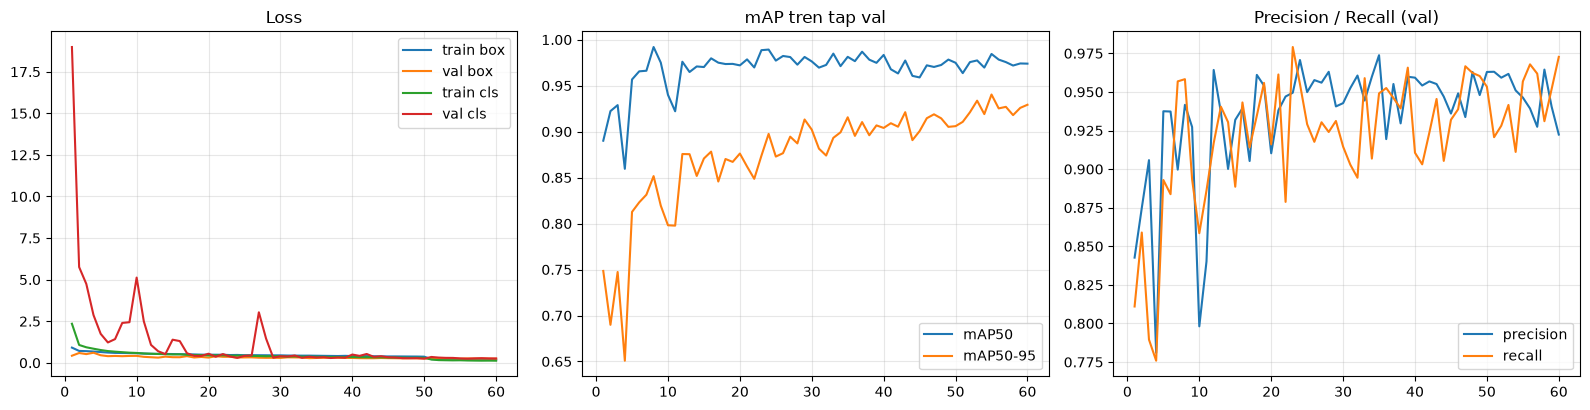

Epoch tot nhat: 55 | mAP50=0.9845 | mAP50-95=0.9403


In [8]:
# @title Do thi qua trinh huan luyen
res = pd.read_csv(TRAIN_DIR / 'results.csv'); res.columns = [c.strip() for c in res.columns]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for k, lab in [('train/box_loss', 'train box'), ('val/box_loss', 'val box'),
               ('train/cls_loss', 'train cls'), ('val/cls_loss', 'val cls')]:
    ax[0].plot(res['epoch'], res[k], label=lab)
ax[0].set_title('Loss'); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(res['epoch'], res['metrics/mAP50(B)'], label='mAP50')
ax[1].plot(res['epoch'], res['metrics/mAP50-95(B)'], label='mAP50-95')
ax[1].set_title('mAP tren tap val'); ax[1].legend(); ax[1].grid(alpha=.3)
ax[2].plot(res['epoch'], res['metrics/precision(B)'], label='precision')
ax[2].plot(res['epoch'], res['metrics/recall(B)'], label='recall')
ax[2].set_title('Precision / Recall (val)'); ax[2].legend(); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUTPUT_DIR / 'training_curves.png', dpi=150); plt.show()
best = res.loc[res['metrics/mAP50-95(B)'].idxmax()]
print(f"Epoch tot nhat: {int(best['epoch'])} | mAP50={best['metrics/mAP50(B)']:.4f} | mAP50-95={best['metrics/mAP50-95(B)']:.4f}")

## Bước 7: Đánh giá trên tập TEST (chưa từng dùng khi huấn luyện)
**a) Chỉ số phát hiện chuẩn (mAP)** theo từng mệnh giá.

**b) Chỉ số cấp ảnh theo đúng cách app dùng:** mỗi ảnh lấy khung tin cậy cao nhất; nếu ≥ `APP_CONF` thì đọc mệnh giá, ngược lại coi là "không có tiền". Ba lỗi cần quan tâm:
- **Đọc sai mệnh giá** (nguy hiểm nhất): có tiền nhưng đọc nhầm sang mệnh giá khác.
- **Bỏ sót tiền**: có tiền nhưng app không đọc.
- **Báo nhầm**: ảnh không có tiền mà app vẫn đọc mệnh giá.

In [9]:
# @title a) mAP tren tap test
best_model = YOLO(str(BEST_PT))
test_metrics = best_model.val(data=str(data_yaml), split='test', imgsz=IMG_SIZE, batch=BATCH,
                              project=str(OUTPUT_DIR), name='test', exist_ok=True, plots=True, verbose=False)
per_class = pd.DataFrame({
    'lop': [CLASS_NAMES[i] for i in test_metrics.box.ap_class_index],
    'precision': test_metrics.box.p, 'recall': test_metrics.box.r,
    'mAP50': test_metrics.box.ap50, 'mAP50-95': test_metrics.box.ap,
}).round(4)
print(per_class.to_string(index=False))
print(f'\nTONG: mAP50={test_metrics.box.map50:.4f} | mAP50-95={test_metrics.box.map:.4f} | '
      f'precision={test_metrics.box.mp:.4f} | recall={test_metrics.box.mr:.4f}')

Ultralytics 8.4.200  Python-3.11.9 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)


Model summary (fused): 73 layers, 3,134,651 parameters, 0 gradients, 8.6 GFLOPs


val: Fast image access  (ping: 0.1±0.0 ms, read: 98.9±55.8 MB/s, size: 42.8 KB)


val: Scanning C:\Personal_data\CDCNTT\Project\vision_assist\ml_training\data\currency_yolo\labels\test... 130 images, 61 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 130/130 2.5Kit/s 0.1s

val: New cache created: C:\Personal_data\CDCNTT\Project\vision_assist\ml_training\data\currency_yolo\labels\test.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 11% ━─────────── 1/9 44.6s/it 13.4s<5:56

... (8 outputs left out)

                   all        130         69       0.94       0.97      0.985      0.931


Speed: 2.0ms preprocess, 6.5ms inference, 0.0ms loss, 0.7ms postprocess per image


Results saved to C:\Personal_data\CDCNTT\Project\vision_assist\ml_training\outputs\currency_yolo\test


 lop  precision  recall  mAP50  mAP50-95
  1k     0.9653  1.0000 0.9950    0.9950
 10k     1.0000  0.8625 0.9950    0.8495
100k     0.9614  1.0000 0.9950    0.9500
  2k     0.9404  1.0000 0.9950    0.9950
 20k     0.8522  1.0000 0.9950    0.9268
200k     0.9187  1.0000 0.9950    0.8883
  5k     0.8740  1.0000 0.9117    0.9001
 50k     0.9501  1.0000 0.9950    0.9486
500k     1.0000  0.8717 0.9840    0.9228

TONG: mAP50=0.9845 | mAP50-95=0.9307 | precision=0.9402 | recall=0.9705


Anh test: 130 (69 co tien, 61 none), nguong APP_CONF=0.5
- Do chinh xac cap anh:        98.46%
- Doc SAI menh gia:            1.45%  (nguy hiem nhat)
- Bo sot tien:                 0.00%
- Bao nham (none -> tien):     1.64%


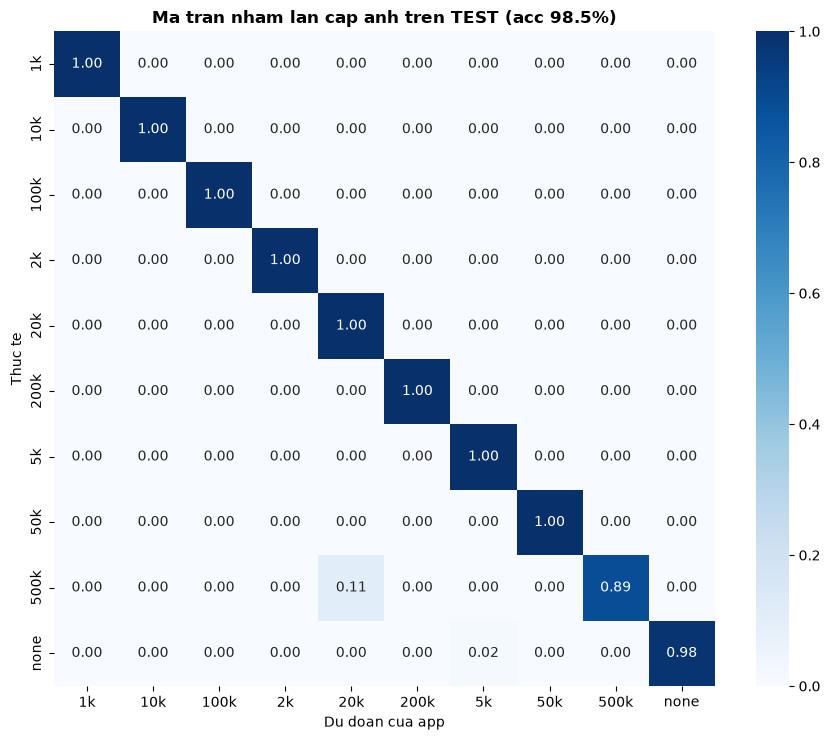

In [10]:
# @title b) Chi so cap anh theo cach app su dung
test_imgs = sorted((DATASET_DIR / 'images' / 'test').glob('*.jpg'))
NONE_IDX = len(CLASS_NAMES)
labels_all = CLASS_NAMES + ['none']
y_true, y_pred, confs = [], [], []
for i in range(0, len(test_imgs), 32):
    batch = test_imgs[i:i + 32]
    for p, r in zip(batch, best_model.predict([str(x) for x in batch], imgsz=IMG_SIZE, conf=0.1, verbose=False)):
        lines = [l.split() for l in (DATASET_DIR / 'labels' / 'test' / (p.stem + '.txt')).read_text().splitlines() if l.strip()]
        y_true.append(int(lines[0][0]) if lines else NONE_IDX)
        if len(r.boxes):
            j = int(r.boxes.conf.argmax()); c = float(r.boxes.conf[j]); confs.append(c)
            y_pred.append(int(r.boxes.cls[j]) if c >= APP_CONF else NONE_IDX)
        else:
            confs.append(0.0); y_pred.append(NONE_IDX)
y_true, y_pred = np.array(y_true), np.array(y_pred)
money = y_true != NONE_IDX
img_acc = float((y_true == y_pred).mean())
wrong_denom = float(((y_pred != y_true) & (y_pred != NONE_IDX) & money).sum() / money.sum())
missed = float(((y_pred == NONE_IDX) & money).sum() / money.sum())
false_alarm = float(((y_pred != NONE_IDX) & ~money).sum() / max(1, (~money).sum()))
print('=' * 60)
print(f'Anh test: {len(y_true)} ({money.sum()} co tien, {(~money).sum()} none), nguong APP_CONF={APP_CONF}')
print(f'- Do chinh xac cap anh:        {img_acc * 100:.2f}%')
print(f'- Doc SAI menh gia:            {wrong_denom * 100:.2f}%  (nguy hiem nhat)')
print(f'- Bo sot tien:                 {missed * 100:.2f}%')
print(f'- Bao nham (none -> tien):     {false_alarm * 100:.2f}%')
print('=' * 60)

from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_true, y_pred, labels=list(range(len(labels_all))), normalize='true')
plt.figure(figsize=(9, 7.5))
sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', xticklabels=labels_all, yticklabels=labels_all)
plt.title(f'Ma tran nham lan cap anh tren TEST (acc {img_acc * 100:.1f}%)', fontweight='bold')
plt.xlabel('Du doan cua app'); plt.ylabel('Thuc te'); plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'confusion_matrix_app_level.png', dpi=150); plt.show()

In [11]:
# @title Ty le loi theo nguong tin cay (de chon nguong cho app)
raw = []
for i in range(0, len(test_imgs), 32):
    batch = test_imgs[i:i + 32]
    for r in best_model.predict([str(x) for x in batch], imgsz=IMG_SIZE, conf=0.05, verbose=False):
        if len(r.boxes):
            j = int(r.boxes.conf.argmax()); raw.append((int(r.boxes.cls[j]), float(r.boxes.conf[j])))
        else:
            raw.append((NONE_IDX, 0.0))
rows = []
for th in (0.25, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9):
    pred = np.array([c if p >= th else NONE_IDX for c, p in raw])
    rows.append({'nguong': th,
                 'chinh xac %': round(100 * (pred == y_true).mean(), 2),
                 'doc sai menh gia %': round(100 * ((pred != y_true) & (pred != NONE_IDX) & money).sum() / money.sum(), 2),
                 'bo sot tien %': round(100 * ((pred == NONE_IDX) & money).sum() / money.sum(), 2),
                 'bao nham %': round(100 * ((pred != NONE_IDX) & ~money).sum() / max(1, (~money).sum()), 2)})
thr_df = pd.DataFrame(rows)
print(thr_df.to_string(index=False))

 nguong  chinh xac %  doc sai menh gia %  bo sot tien %  bao nham %
   0.25        97.69                1.45           0.00        3.28
   0.40        97.69                1.45           0.00        3.28
   0.50        98.46                1.45           0.00        1.64
   0.60        97.69                1.45           1.45        1.64
   0.70        96.92                1.45           2.90        1.64
   0.80        94.62                0.00           8.70        1.64
   0.90        83.85                0.00          28.99        1.64


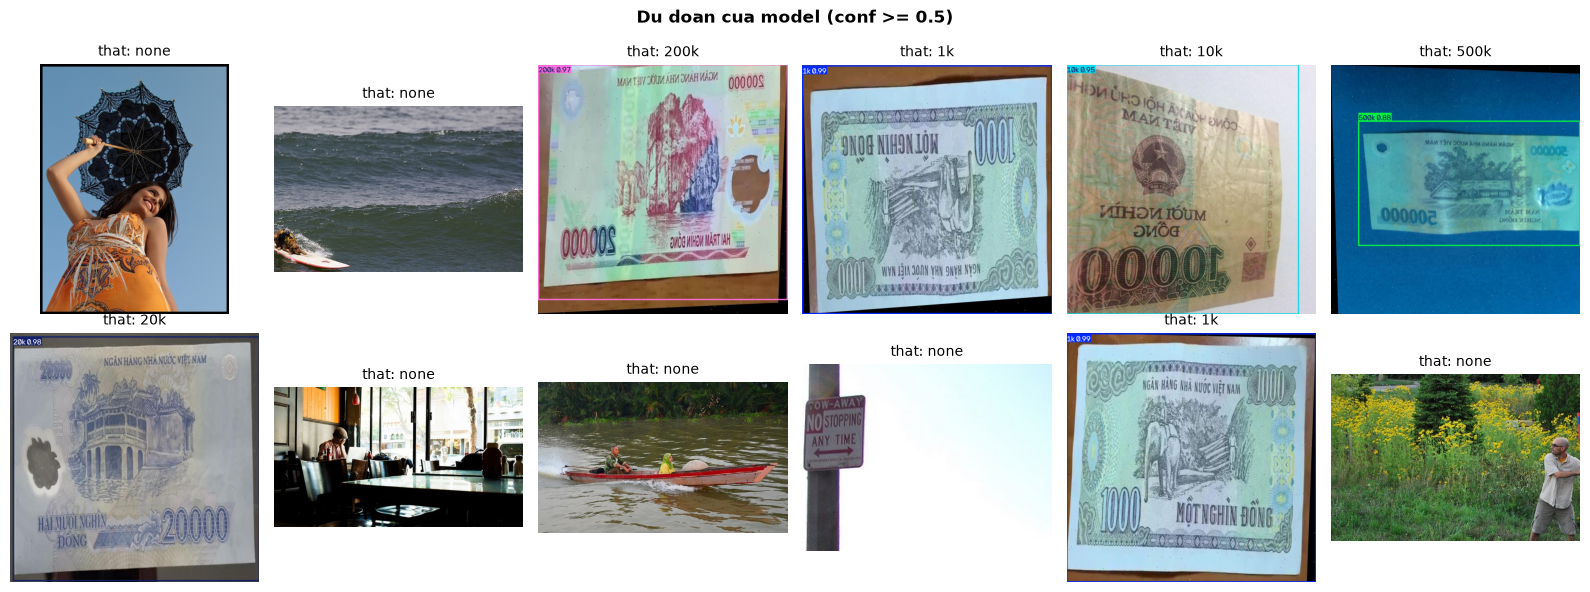

In [12]:
# @title Vi du du doan tren anh test
sample = random.Random(3).sample(test_imgs, 12)
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for ax, p, r in zip(axes.flat, sample, best_model.predict([str(x) for x in sample], imgsz=IMG_SIZE, conf=APP_CONF, verbose=False)):
    ax.imshow(r.plot()[:, :, ::-1]); ax.axis('off')
    lines = [l.split() for l in (DATASET_DIR / 'labels' / 'test' / (p.stem + '.txt')).read_text().splitlines() if l.strip()]
    ax.set_title('that: ' + (CLASS_NAMES[int(lines[0][0])] if lines else 'none'), fontsize=10)
plt.suptitle(f'Du doan cua model (conf >= {APP_CONF})', fontweight='bold'); plt.tight_layout(); plt.show()

## Bước 8: Xuất model và lưu kết quả
- **ONNX** (opset 12, kích thước cố định 640): luôn xuất được.
- **TFLite**: Ultralytics chỉ hỗ trợ xuất TFLite trên Linux/macOS. Trên Windows, chuyển ONNX → TFLite bằng `onnx2tf` (cùng quy trình đã dùng cho model vật cản), hoặc chạy ô này trên Colab.
- Lưu `currency_yolo_labels.txt` theo đúng thứ tự chỉ số lớp, cùng `metrics.json`.

In [13]:
# @title Xuat ONNX / TFLite, file nhan va metrics.json
onnx_path = Path(best_model.export(format='onnx', imgsz=IMG_SIZE, opset=12, simplify=True, dynamic=False))
shutil.copy2(onnx_path, OUTPUT_DIR / 'currency_yolov8n.onnx')
print(f'[SUCCESS] ONNX: {OUTPUT_DIR / "currency_yolov8n.onnx"} ({onnx_path.stat().st_size / 1024**2:.1f} MB)')

tflite_path = None
if platform.system() != 'Windows':
    try:
        tflite_path = Path(best_model.export(format='tflite', imgsz=IMG_SIZE, half=True))
        shutil.copy2(tflite_path, OUTPUT_DIR / 'currency_yolov8n.tflite')
        print(f'[SUCCESS] TFLite: {OUTPUT_DIR / "currency_yolov8n.tflite"}')
    except Exception as e:
        print(f'[WARNING] Xuat TFLite that bai: {e}')
else:
    print('[INFO] Windows: chuyen ONNX -> TFLite bang onnx2tf (xem README trong outputs).')

(OUTPUT_DIR / 'currency_yolo_labels.txt').write_text('\n'.join(CLASS_NAMES) + '\n', encoding='utf-8')
metrics = {
    'timestamp': time.strftime('%Y-%m-%dT%H:%M:%S'),
    'model': MODEL_NAME, 'imgsz': IMG_SIZE, 'epochs_config': EPOCHS, 'batch': BATCH,
    'ultralytics': ultralytics.__version__, 'torch': torch.__version__,
    'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    'dataset': {'source': 'Roboflow Universe danhdz/tienviet v5 (CC BY 4.0) + COCO val2017 (none)',
                'split_counts': split_df.to_dict(orient='records'), 'none_percent': round(none_pct, 2),
                'groups': int(df.group.nunique()), 'leaked_groups_after_split': len(leak)},
    'class_names': CLASS_NAMES,
    'test_detection': {'mAP50': float(test_metrics.box.map50), 'mAP50_95': float(test_metrics.box.map),
                       'precision': float(test_metrics.box.mp), 'recall': float(test_metrics.box.mr),
                       'per_class': per_class.to_dict(orient='records')},
    'test_app_level': {'app_conf': APP_CONF, 'accuracy': img_acc, 'wrong_denomination_rate': wrong_denom,
                       'missed_money_rate': missed, 'false_alarm_rate': false_alarm,
                       'by_threshold': thr_df.to_dict(orient='records')},
    'notes': ['Test chia theo nhom anh goc + phash, nhung van cung nguon chup voi train: '
              'can kiem thu tren dien thoai voi tien that truoc khi khang dinh do chinh xac thuc te.'],
}
(OUTPUT_DIR / 'metrics.json').write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding='utf-8')
print(f'[SUCCESS] Da luu metrics.json va currency_yolo_labels.txt vao {OUTPUT_DIR}')
print(json.dumps({k: metrics[k] for k in ('test_detection', 'test_app_level')}, ensure_ascii=False, indent=2)[:1500])

Ultralytics 8.4.200  Python-3.11.9 torch-2.5.1+cu121 CPU (AMD Ryzen 7 7435HS)


Model summary (fused): 73 layers, 3,134,651 parameters, 0 gradients, 8.6 GFLOPs



PyTorch: starting from 'C:\Personal_data\CDCNTT\Project\vision_assist\ml_training\outputs\currency_yolo\train\weights\best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 13, 8400) (6.2 MB)



ONNX: starting export with onnx 1.23.2 opset 12...


ONNX: slimming with onnxslim 0.1.98...


ONNX: export success  1.5s, saved as 'C:\Personal_data\CDCNTT\Project\vision_assist\ml_training\outputs\currency_yolo\train\weights\best.onnx' (12.2 MB)



Export complete (1.7s)
Results saved to C:\Personal_data\CDCNTT\Project\vision_assist\ml_training\outputs\currency_yolo\train\weights\best.onnx
Predict:         yolo predict task=detect model=C:\Personal_data\CDCNTT\Project\vision_assist\ml_training\outputs\currency_yolo\train\weights\best.onnx imgsz=640 
Validate:        yolo val task=detect model=C:\Personal_data\CDCNTT\Project\vision_assist\ml_training\outputs\currency_yolo\train\weights\best.onnx imgsz=640 data=C:\Personal_data\CDCNTT\Project\vision_assist\ml_training\data\currency_yolo\data.yaml 
Visualize:       https://netron.app


[SUCCESS] ONNX: C:\Personal_data\CDCNTT\Project\vision_assist\ml_training\outputs\currency_yolo\currency_yolov8n.onnx (12.2 MB)
[INFO] Windows: chuyen ONNX -> TFLite bang onnx2tf (xem README trong outputs).
[SUCCESS] Da luu metrics.json va currency_yolo_labels.txt vao C:\Personal_data\CDCNTT\Project\vision_assist\ml_training\outputs\currency_yolo
{
  "test_detection": {
    "mAP50": 0.9845185185185186,
    "mAP50_95": 0.930676234567901,
    "precision": 0.9402390799589951,
    "recall": 0.9704626629326645,
    "per_class": [
      {
        "lop": "1k",
        "precision": 0.9653,
        "recall": 1.0,
        "mAP50": 0.995,
        "mAP50-95": 0.995
      },
      {
        "lop": "10k",
        "precision": 1.0,
        "recall": 0.8625,
        "mAP50": 0.995,
        "mAP50-95": 0.8495
      },
      {
        "lop": "100k",
        "precision": 0.9614,
        "recall": 1.0,
        "mAP50": 0.995,
        "mAP50-95": 0.95
      },
      {
        "lop": "2k",
        "precisio

---
### Lưu ý khi báo cáo kết quả
- Tập test đã được chia **theo nhóm ảnh gốc và ảnh gần trùng**, nên không còn rò rỉ trực tiếp như cách chia gốc của Roboflow. Nhưng ảnh test vẫn cùng nguồn chụp, cùng các tờ tiền với ảnh train. Điểm test **chưa phản ánh** độ chính xác khi người khiếm thị dùng ngoài đời.
- Ảnh Roboflow đã bị **kéo giãn về 640×640**, nên tờ tiền trong dataset bị méo so với ảnh camera thật. Khi tích hợp vào app cần chọn cách tiền xử lý (letterbox hay kéo giãn) và kiểm chứng trên điện thoại.
- **Bắt buộc thử trên điện thoại thật** với tiền thật: cả hai mặt, ngang và dọc, nhiều kiểu ánh sáng, có tay cầm.